# Hybrid 05 · Explaining departures from the ECD thresholds (SHAP)

**Question:** when the hybrid predicts a tissue's recorded grade correctly but the ECD tree does not, which feature groups are associated with the hybrid's prediction, compared with tissues where both are correct or only the tree is correct?

**Derived from:** `notebooks/images/12_threshold_departure_explainability.ipynb` (exploratory; protocol not committed separately before execution).
**Cohort / design:** K4 (470 tissues), the same folds, hybrid (PCA 16, notebook 05 settings) and ECD tree as Hybrid 04. **Runtime:** about 1 minute.

> **SHAP describes the model, not the cornea.** Values are associations inside a fitted model: not clinical explanations of the specialists' grades, not causal evidence, and not proof that an image pattern is a real clinical signal. No hypothesis tests are run.

Set up paths, the primary cohort and the feature groups (ECD, count and area are grouped because ECD = count / area; CV and SD because CV ≈ SD / mean cell area).

In [1]:
import sys
import warnings
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.base import clone

import cleaned_setup as cs
import modeling_setup as ms

warnings.filterwarnings("ignore", category=UserWarning)
k3, folds, has_ecd = cs.primary_cohort()
X, y, donors = cs.feature_matrix(k3)

FEATURE_GROUPS = {
    "ECD-derived": ["ECD_CD_cells_per_mm2", "Total_Cell_Count", "Total_Area_um2"],
    "Variability": ["CV", "SD"],
    "HEX": ["HEX_percent"],
    "Slit-lamp: stroma": [f for f in ms.ALL_FEATURES if f.startswith("Stroma_")],
    "Slit-lamp: epithelium": [f for f in ms.ALL_FEATURES if f.startswith("Epi_")],
    "Slit-lamp: endothelium": [f for f in ms.ALL_FEATURES if f.startswith("Endo_")],
    "Slit-lamp: Descemet": [f for f in ms.ALL_FEATURES if f.startswith("Descemet_")],
}
assert sorted(f for v in FEATURE_GROUPS.values() for f in v) == sorted(ms.ALL_FEATURES)
GROUPS = list(FEATURE_GROUPS) + ["Image"]
print("shap", shap.__version__, "| groups:", GROUPS)

shap 0.51.0 | groups: ['ECD-derived', 'Variability', 'HEX', 'Slit-lamp: stroma', 'Slit-lamp: epithelium', 'Slit-lamp: endothelium', 'Slit-lamp: Descemet', 'Image']


Map every transformed column (including one-hot and missing-category columns) back to its source feature's group; the 16 PCA components form the image group.

In [2]:
def source_group(column):
    if column.startswith("image__"):
        return "Image"
    remainder = column.split("__", 2)[2]
    feature = max((f for f in ms.ALL_FEATURES if remainder == f or remainder.startswith(f + "_")), key=len)
    return next(group for group, members in FEATURE_GROUPS.items() if feature in members)

## 1. Out-of-fold predictions and SHAP values

For each fold, fit the hybrid and the ECD tree on the training tissues, then explain each held-out K4 tissue with the fold model that **did not** train on it (TreeSHAP, path-dependent), for the probability of its **recorded** grade. Positive values push the model toward the recorded grade. Additivity is checked in every fold.

In [3]:
records, shap_rows, fold_rows, max_error = [], [], [], 0.0
for repeat in range(ms.N_REPEATS):
    for fold, (train, test) in enumerate(ms.iter_donor_folds(folds, k3["Tissue_ID"], repeat)):
        assert set(donors[train]).isdisjoint(donors[test]), "Donor leak"
        eval_test, train_ecd = test[has_ecd[test]], train[has_ecd[train]]
        hybrid = clone(cs.rf_pipeline(n_components=16)).fit(X.iloc[train], y[train])
        tree = cs.ecd_tree().fit(X.iloc[train_ecd], y[train_ecd])
        hybrid_pred, tree_pred = hybrid.predict(X.iloc[eval_test]), tree.predict(X.iloc[eval_test])
        for name, pred in [("Hybrid", hybrid_pred), ("ECD tree", tree_pred)]:
            fold_rows.append({"Model": name, "Repeat": repeat, "Fold": fold, **{m: fn(y[eval_test], pred) for m, fn in cs.METRICS.items()}})

        transformer, forest = hybrid.named_steps["features"], hybrid.named_steps["classifier"]
        Z = transformer.transform(X.iloc[eval_test])
        explainer = shap.TreeExplainer(forest, feature_perturbation="tree_path_dependent")
        values = np.asarray(explainer.shap_values(Z))  # (tissues, columns, classes)
        error = np.abs(values.sum(axis=1) + np.asarray(explainer.expected_value) - forest.predict_proba(Z)).max()
        max_error = max(max_error, error)
        assert error < 1e-6, "SHAP additivity failed"

        column_groups = np.array([source_group(c) for c in transformer.get_feature_names_out()])
        class_index = {c: i for i, c in enumerate(forest.classes_)}
        toward_recorded = values[np.arange(len(eval_test)), :, [class_index[g] for g in y[eval_test]]]
        for i, row in enumerate(eval_test):
            records.append({"Row": row, "Repeat": repeat, "Recorded": y[row], "Hybrid": hybrid_pred[i], "Tree": tree_pred[i]})
            shap_rows.append({g: toward_recorded[i, column_groups == g].sum() for g in GROUPS})
cases = pd.concat([pd.DataFrame(records), pd.DataFrame(shap_rows)], axis=1)
print(f"{len(cases)} tissue–repeat pairs; max SHAP additivity error {max_error:.1e}")

2350 tissue–repeat pairs; max SHAP additivity error 1.6e-15


Reproducibility checks: the refitted models must reproduce notebook 11's fold scores, and the grouped SHAP values must equal notebook 12's saved values.

In [4]:
saved = pd.read_csv(ms.PROCESSED_DIR / "fitted_ecd_fold_scores.csv")
ours = pd.DataFrame(fold_rows)
for model in ["Hybrid", "ECD tree"]:
    a = ours[ours["Model"] == model].set_index(["Repeat", "Fold"])[list(cs.METRICS)].sort_index()
    b = saved[saved["Model"] == model].set_index(["Repeat", "Fold"])[list(cs.METRICS)].sort_index()
    print(f"{model}: max absolute difference from notebook 11 = {(a - b).abs().to_numpy().max():.1e}")
saved12 = pd.read_csv(ms.PROCESSED_DIR / "threshold_departure_shap.csv")
print(f"Grouped SHAP, max absolute difference from notebook 12 = {np.abs(cases[GROUPS].to_numpy() - saved12[GROUPS].to_numpy()).max():.1e}")

Hybrid: max absolute difference from notebook 11 = 1.1e-16
ECD tree: max absolute difference from notebook 11 = 0.0e+00
Grouped SHAP, max absolute difference from notebook 12 = 1.0e-16


## 2. Case groups

Classify each tissue–repeat pair by which model is correct, and the direction of departure (recorded grade below the tree's ECD-based grade = downgrade).

In [5]:
RANK = {"A+": 2, "A": 1, "B": 0}
hybrid_ok, tree_ok = cases["Hybrid"] == cases["Recorded"], cases["Tree"] == cases["Recorded"]
cases["Group"] = np.select([hybrid_ok & ~tree_ok, hybrid_ok & tree_ok, ~hybrid_ok & tree_ok],
                           ["Hybrid-only correct", "Both correct", "Tree-only correct"], default="Both wrong")
cases["Departure"] = np.select([cases["Recorded"].map(RANK) < cases["Tree"].map(RANK), cases["Recorded"].map(RANK) > cases["Tree"].map(RANK)],
                               ["Downgrade", "Upgrade"], default="None")
CASE_GROUPS = ["Hybrid-only correct", "Both correct", "Tree-only correct", "Both wrong"]
pd.DataFrame({
    "Tissue–repeat pairs": cases["Group"].value_counts(),
    "Unique tissues": cases.groupby("Group")["Row"].nunique(),
    "Downgrades": cases[cases["Departure"] == "Downgrade"]["Group"].value_counts(),
}).reindex(CASE_GROUPS).fillna(0).astype(int)

,Tissue–repeat pairs,Unique tissues,Downgrades
Group,,,
Hybrid-only correct,133,37,131
Both correct,1739,366,0
Tree-only correct,151,58,0
Both wrong,327,78,314


How many of the downgrades does the hybrid recover, and how often does it depart wrongly?

In [6]:
downgrade_pairs = (cases["Departure"] == "Downgrade").sum()
recovered = ((cases["Group"] == "Hybrid-only correct") & (cases["Departure"] == "Downgrade")).sum()
wrong_departures = (cases["Group"] == "Tree-only correct").sum()
consistency = cases.assign(H=cases["Group"] == "Hybrid-only correct").groupby("Row")["H"].sum()
print(f"Hybrid recovers {recovered} of {downgrade_pairs} downgrade pairs ({recovered / downgrade_pairs:.0%}); "
      f"it departs wrongly in {wrong_departures} pairs (tree-only correct)")
print(f"Tissues hybrid-only correct in ≥1 repeat: {(consistency >= 1).sum()}, ≥3: {(consistency >= 3).sum()}, all 5: {(consistency == 5).sum()}")

Hybrid recovers 131 of 445 downgrade pairs (29%); it departs wrongly in 151 pairs (tree-only correct)
Tissues hybrid-only correct in ≥1 repeat: 37, ≥3: 30, all 5: 14


## 3. Grouped SHAP toward the recorded grade

Mean signed grouped SHAP per case group. The tree-only-correct group is the essential control: a group that is large in **both** disagreement directions indicates model reliance, not useful signal.

In [7]:
means = cases[cases["Group"].isin(CASE_GROUPS[:3])].groupby("Group")[GROUPS].mean().reindex(CASE_GROUPS[:3]).T
means.round(3)

Group,Hybrid-only correct,Both correct,Tree-only correct
ECD-derived,0.029,0.164,0.075
Variability,0.027,0.056,-0.000
HEX,0.008,0.004,-0.004
Slit-lamp: stroma,0.019,0.017,0.009
Slit-lamp: epithelium,0.002,0.002,-0.000
Slit-lamp: endothelium,-0.001,0.003,0.000
Slit-lamp: Descemet,0.000,0.006,0.000
Image,0.063,0.050,-0.033


The same means as a chart (image components have no clinical labels, so only their magnitude is reported).

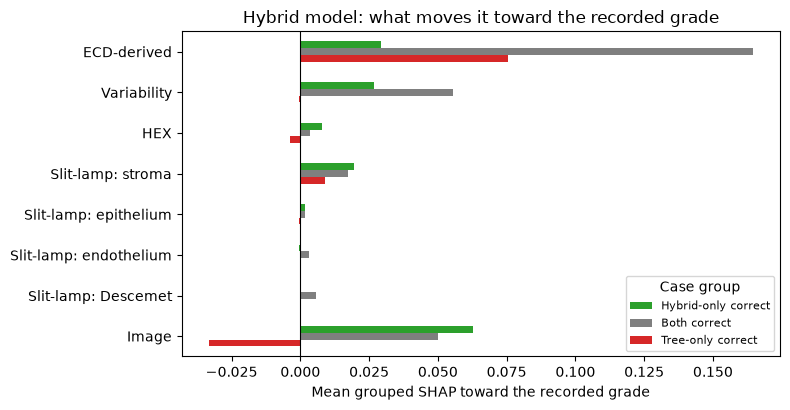

In [8]:
ax = means.plot.barh(figsize=(8, 4.2), color=["tab:green", "tab:grey", "tab:red"])
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set(xlabel="Mean grouped SHAP toward the recorded grade", title="Hybrid model: what moves it toward the recorded grade")
ax.legend(title="Case group", fontsize=8)
plt.tight_layout()
plt.show()

Stability across the 5 repeats in hybrid-only-correct cases (a pattern counts as stable if it holds in at least 4 of 5).

In [9]:
per_repeat = cases[cases["Group"] == "Hybrid-only correct"].groupby("Repeat")[GROUPS].mean()
pd.DataFrame({"Min": per_repeat.min(), "Max": per_repeat.max(), "Repeats positive": (per_repeat > 0).sum(),
              "Repeats ranked first": per_repeat.idxmax(axis=1).value_counts().reindex(GROUPS, fill_value=0)}).round(3)

,Min,Max,Repeats positive,Repeats ranked first
ECD-derived,0.024,0.039,5,0
Variability,0.020,0.029,5,0
HEX,0.005,0.010,5,0
Slit-lamp: stroma,0.012,0.029,5,0
Slit-lamp: epithelium,0.000,0.003,5,0
Slit-lamp: endothelium,-0.003,0.002,1,0
Slit-lamp: Descemet,-0.001,0.002,3,0
Image,0.057,0.072,5,5


## 4. Downgraded tissues in the raw data (not SHAP; descriptive)

Hybrid-only-correct downgrades where the tree predicted A+, against both-correct tissues where the tree predicted A+ (unique tissues; aggregates only).

In [10]:
def prevalence(rows):
    frame = k3.loc[sorted(rows)]
    binary = pd.Series({f: frame[f].eq(1).sum() / frame[f].notna().sum() for f in ms.CLINICAL_BINARY_FEATURES})
    return binary, frame[ms.NUMERIC_FEATURES].median(), len(frame)


downgrades = cases[(cases["Group"] == "Hybrid-only correct") & (cases["Departure"] == "Downgrade") & (cases["Tree"] == "A+")]
reference = cases[(cases["Group"] == "Both correct") & (cases["Tree"] == "A+")]
(case_bin, case_konan, n_case), (ref_bin, ref_konan, n_ref) = prevalence(set(downgrades["Row"])), prevalence(set(reference["Row"]))
print(f"Downgrades: {n_case} tissues | both correct: {n_ref} tissues")
display(pd.DataFrame({"Downgrades": case_konan, "Both correct": ref_konan}).round(0).rename_axis("Median"))
pd.DataFrame({"Downgrades": case_bin, "Both correct": ref_bin, "Difference": case_bin - ref_bin}).sort_values("Difference", ascending=False).head(6).round(2)

Downgrades: 33 tissues | both correct: 230 tissues


,Downgrades,Both correct
Median,,
ECD_CD_cells_per_mm2,2611.0,2821.0
CV,40.0,37.0
HEX_percent,50.0,55.0
SD,149.0,130.0
Total_Cell_Count,106.0,108.0
Total_Area_um2,41202.0,38630.0


,Downgrades,Both correct,Difference
Endo_Has_Cell_Dropout,0.27,0.12,0.15
Stroma_Has_Scar,0.15,0.00,0.15
Epi_Has_Arcus,0.70,0.55,0.15
Epi_Has_Exposure,0.58,0.51,0.07
Epi_Has_Haze,0.09,0.03,0.06
Stroma_Has_Edema,0.06,0.01,0.05


## Interpretation (exploratory)

- The hybrid recovers about 29% of tissues recorded below the ECD tree's grade (131 of 445 downgrade pairs), but makes a similar number of wrong departures (151). Its departures are right about as often as wrong.
- **Image** has the largest contribution in hybrid-only-correct cases (every repeat) but pushes the model **away** from the recorded grade in tree-only-correct cases at a similar magnitude: model reliance, not demonstrated image signal.
- **Endothelial variability (CV, SD)** is the more consistent association: positive in hybrid-only-correct cases in all 5 repeats and ≈0 where the hybrid departs wrongly. Stromal findings show a smaller version of the same pattern.
- In the raw data, these downgraded tissues had higher variability, lower HEX, and more stromal scar and cell dropout: clinically plausible, but **hypotheses for clinical review**, not explanations of the specialists' grades.

**Limitations:** SHAP explains this model only, and does not establish causation. The tissues were selected **because** the hybrid predicted them correctly, so features it relies on differ by construction. The model is the untuned notebook 05 hybrid with PCA 16 (the deployed model uses PCA 32 and tuned settings). A model-free comparison of all tissues graded below the ECD thresholds was not run.